# AtmosPredict AI

Integrated Air Quality & Rainfall Prediction Using Machine Learning.

A combined ML project for air quality analysis, AQI prediction, rainfall classification, model evaluation, and advanced data visualization.
- **AQI regression:** estimate `AQI Value` from pollutant AQI values (CO, Ozone, NO₂, PM2.5). Latitude/longitude are kept for geographic exploration, not used as prediction features.
- **Rainfall classification:** predict `rainfall` (`yes`/`no`) from weather measurements. `day` is excluded because it is an index-like field, not a dependable weather signal.
- **Models:** includes XGBoost (`XGBRegressor`, `XGBClassifier`) alongside Random Forest, Extra Trees and baseline models.
- **Evaluation:** held-out test set, cross-validation on training data, suitable metrics, diagnostic charts and feature importance.

> AQI overall values are closely related to the pollutant AQI inputs, so strong AQI scores should not be interpreted as forecasting future air quality. Rainfall has only 366 rows; results may vary and should be interpreted cautiously.

## 1. Install dependencies (if needed)
Run the following in a notebook cell or terminal once.

In [1]:
# If any import is missing, uncomment and run:
# %pip install -r requirements.txt

## 2. Imports and configuration

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
    balanced_accuracy_score, precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBRegressor, XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost isn't installed. Run %pip install xgboost and rerun this cell.")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
if not (DATA_DIR / "Rainfall.csv").exists():
    # Useful if the notebook is launched from its parent folder.
    DATA_DIR = ROOT / "Unified_AQI_Rainfall_ML_Project_Notebook" / "data"

AQI_PATH = DATA_DIR / "AQI-and-Lat-Long-of-Countries.csv"
RAIN_PATH = DATA_DIR / "Rainfall.csv"
print("Data folder:", DATA_DIR.resolve())
print("XGBoost available:", XGBOOST_AVAILABLE)

Data folder: C:\Users\swaru\OneDrive\Desktop\ML\ML Project\data
XGBoost available: True


## 3. Load and inspect both datasets

In [3]:
aqi = pd.read_csv(AQI_PATH)
rain = pd.read_csv(RAIN_PATH)
aqI_cols = {c: c.strip().lower() for c in aqi.columns}
aqi = aqi.rename(columns=aqI_cols)
rain = rain.rename(columns={c: c.strip().lower() for c in rain.columns})
rain["rainfall"] = rain["rainfall"].astype(str).str.strip().str.lower()
for col in rain.columns:
    if col != "rainfall":
        rain[col] = pd.to_numeric(rain[col], errors="coerce")

print("AQI shape:", aqi.shape, " | Rainfall shape:", rain.shape)
display(aqi.head())
display(rain.head())
print("AQI missing values:\n", aqi.isna().sum())
print("Rainfall missing values:\n", rain.isna().sum())
display(aqi.describe().T)
display(rain.describe(include="all").T)

AQI shape: (16695, 7)  | Rainfall shape: (366, 12)


,aqi value,co aqi value,ozone aqi value,no2 aqi value,pm2.5 aqi value,lat,lng
0,51,1,36,0,51,44.7444,44.2031
1,41,1,5,1,41,-5.2900,-44.4900
2,41,1,5,1,41,-11.2958,-41.9869
3,66,1,39,2,66,37.1667,15.1833
4,34,1,34,0,20,53.0167,20.8833


,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1,1025.9,19.9,18.3,16.8,13.1,72,49,yes,9.3,80.0,26.3
1,2,1022.0,21.7,18.9,17.2,15.6,81,83,yes,0.6,50.0,15.3
2,3,1019.7,20.3,19.3,18.0,18.4,95,91,yes,0.0,40.0,14.2
3,4,1018.9,22.3,20.6,19.1,18.8,90,88,yes,1.0,50.0,16.9
4,5,1015.9,21.3,20.7,20.2,19.9,95,81,yes,0.0,40.0,13.7


AQI missing values:
 aqi value          0
co aqi value       0
ozone aqi value    0
no2 aqi value      0
pm2.5 aqi value    0
lat                0
lng                0
dtype: int64
Rainfall missing values:
 day              0
pressure         0
maxtemp          0
temparature      0
mintemp          0
dewpoint         0
humidity         0
cloud            0
rainfall         0
sunshine         0
winddirection    1
windspeed        1
dtype: int64


,count,mean,std,min,25%,50%,75%,max
aqi value,16695.0,62.998682,43.091971,7.0000,38.50000,52.0000,69.0000,500.0000
co aqi value,16695.0,1.342138,2.371379,0.0000,1.00000,1.0000,1.0000,133.0000
ozone aqi value,16695.0,31.767355,22.839343,0.0000,20.00000,29.0000,38.0000,222.0000
no2 aqi value,16695.0,3.819647,5.880677,0.0000,0.00000,2.0000,5.0000,91.0000
pm2.5 aqi value,16695.0,59.821324,43.208298,0.0000,34.00000,52.0000,69.0000,500.0000
lat,16695.0,30.267148,22.947398,-54.8019,16.51545,38.8158,46.6833,70.7670
lng,16695.0,-3.944485,73.037148,-171.7500,-75.18000,5.6431,36.2750,178.0178


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
day,366.0,NaN,NaN,NaN,15.756831,8.823592,1.0,8.0,16.0,23.0,31.0
pressure,366.0,NaN,NaN,NaN,1013.742623,6.414776,998.5,1008.5,1013.0,1018.1,1034.6
maxtemp,366.0,NaN,NaN,NaN,26.191257,5.978343,7.1,21.2,27.75,31.2,36.3
temparature,366.0,NaN,NaN,NaN,23.747268,5.632813,4.9,18.825,25.45,28.6,32.4
mintemp,366.0,NaN,NaN,NaN,21.894536,5.594153,3.1,17.125,23.7,26.575,30.0
dewpoint,366.0,NaN,NaN,NaN,19.989071,5.997021,-0.4,16.125,21.95,25.0,26.7
humidity,366.0,NaN,NaN,NaN,80.177596,10.06247,36.0,75.0,80.5,87.0,98.0
cloud,366.0,NaN,NaN,NaN,71.128415,21.798012,0.0,58.0,80.0,88.0,100.0
rainfall,366,2,yes,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sunshine,366.0,NaN,NaN,NaN,4.419399,3.934398,0.0,0.5,3.5,8.2,12.1


## 4. Dataset overview visualizations

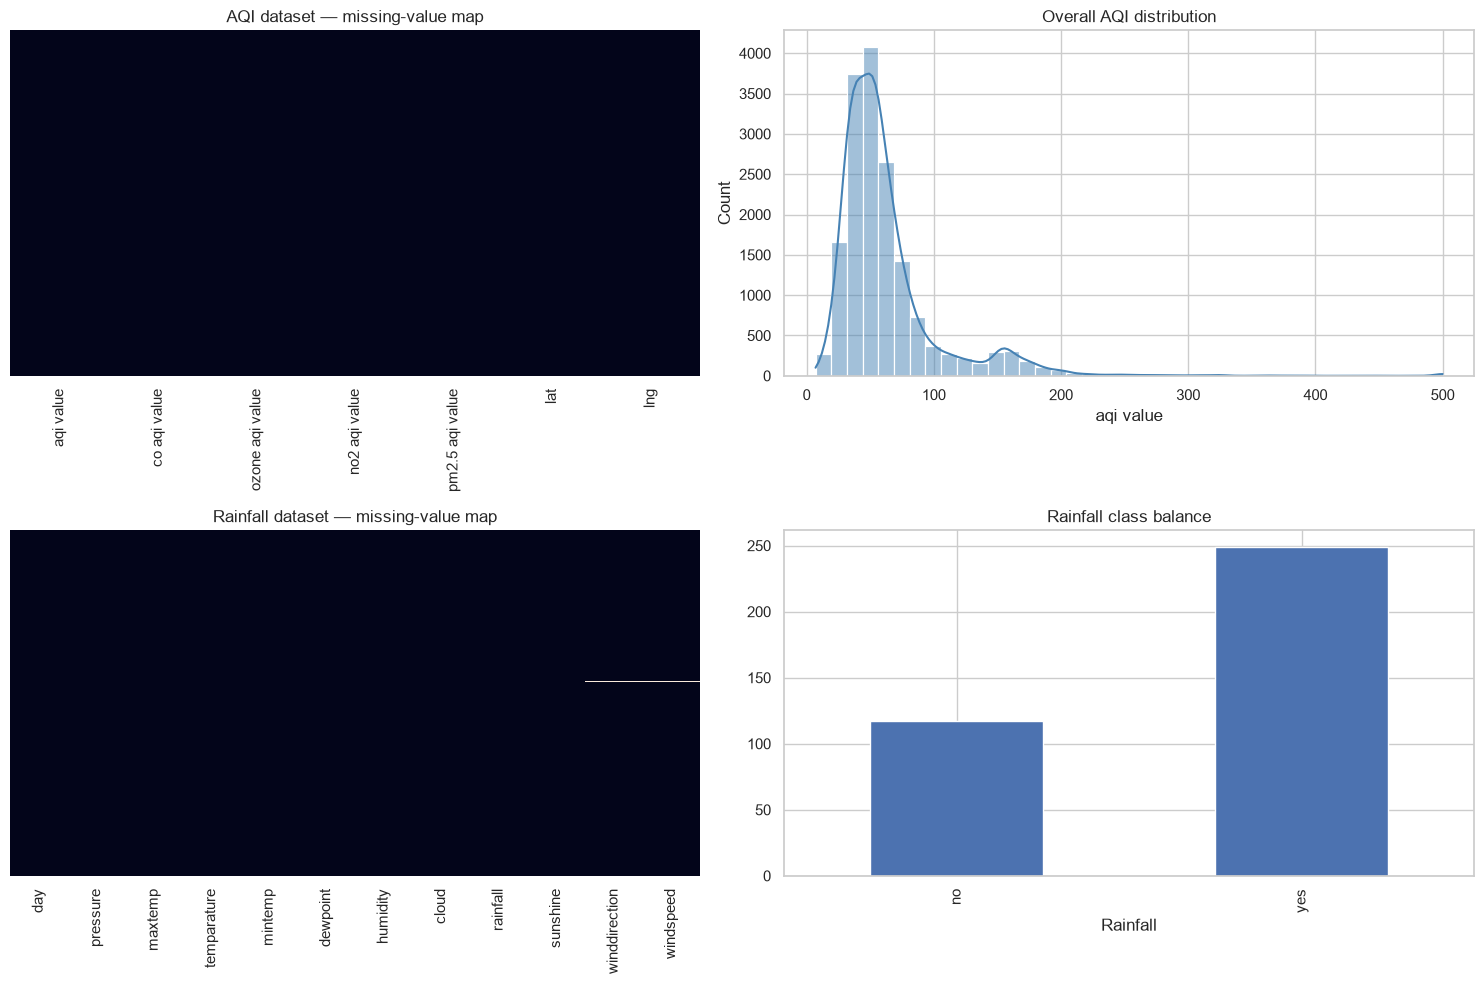

In [4]:
# Missingness and target distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.heatmap(aqi.isna(), cbar=False, yticklabels=False, ax=axes[0,0])
axes[0,0].set_title("AQI dataset — missing-value map")
sns.histplot(aqi["aqi value"], bins=40, kde=True, color="steelblue", ax=axes[0,1])
axes[0,1].set_title("Overall AQI distribution")
sns.heatmap(rain.isna(), cbar=False, yticklabels=False, ax=axes[1,0])
axes[1,0].set_title("Rainfall dataset — missing-value map")
rain["rainfall"].value_counts().reindex(["no", "yes"]).plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("Rainfall class balance"); axes[1,1].set_xlabel("Rainfall")
plt.tight_layout(); plt.show()

fig = px.histogram(aqi, x="aqi value", nbins=50, marginal="box", title="Interactive distribution of AQI")
fig.show()
fig = px.pie(rain, names="rainfall", hole=0.42, title="Rainfall yes/no proportion")
fig.show()

## 5. AQI exploratory data analysis

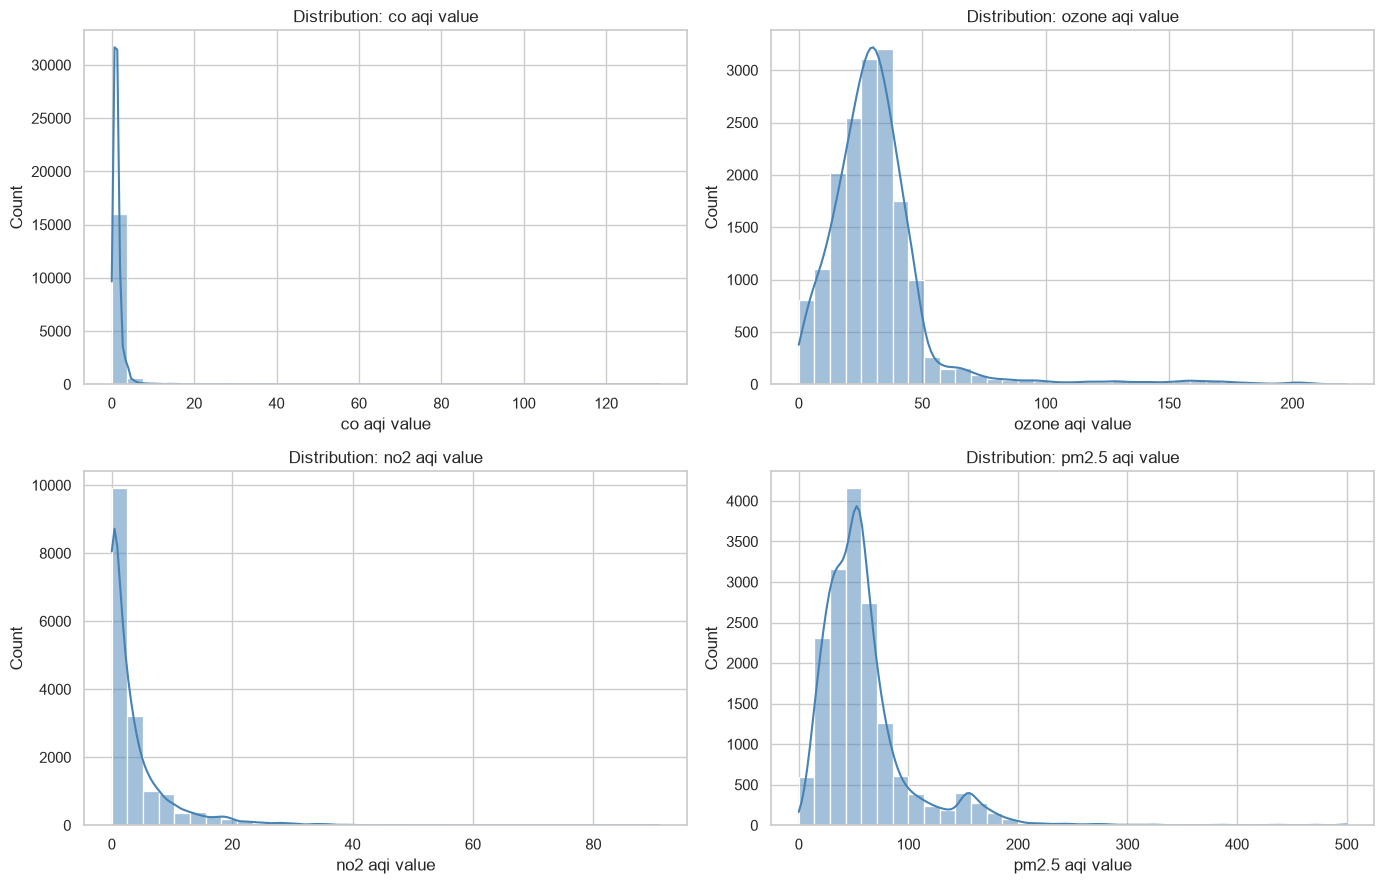

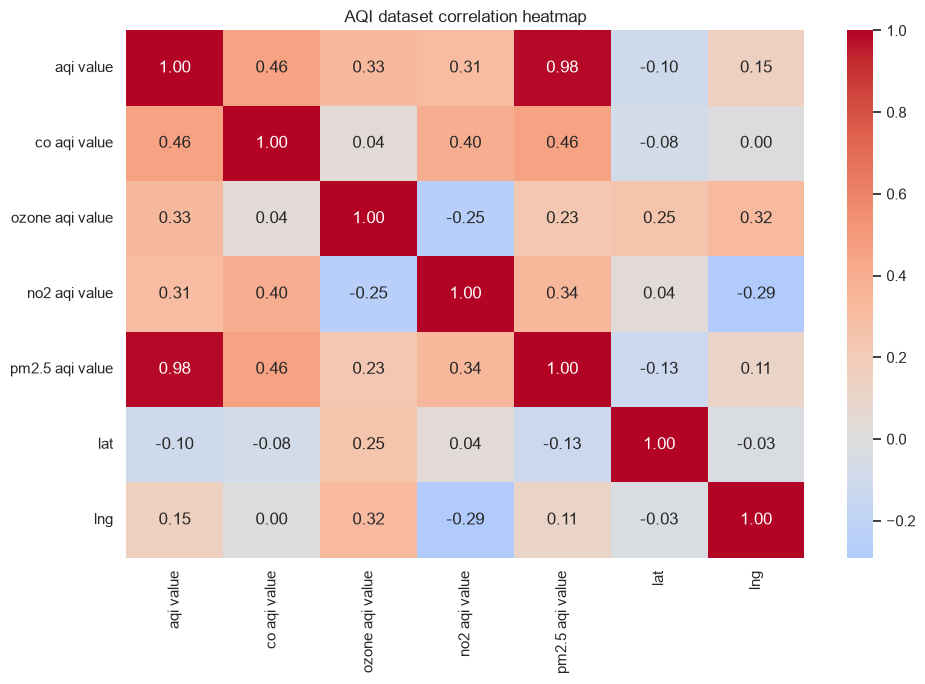

In [5]:
pollutants = ["co aqi value", "ozone aqi value", "no2 aqi value", "pm2.5 aqi value"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, pollutants):
    sns.histplot(aqi[col], bins=35, kde=True, color="steelblue", ax=ax)
    ax.set_title(f"Distribution: {col}")
plt.tight_layout(); plt.show()

numeric_aqi = aqi.select_dtypes(include=np.number)
plt.figure(figsize=(10,7))
sns.heatmap(numeric_aqi.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("AQI dataset correlation heatmap"); plt.tight_layout(); plt.show()

fig = px.scatter_matrix(aqi.sample(min(2500, len(aqi)), random_state=RANDOM_STATE),
    dimensions=pollutants + ["aqi value"], color="aqi value", title="AQI pollutant relationships (sample)")
fig.show()
for col in pollutants:
    fig = px.scatter(aqi.sample(min(3000, len(aqi)), random_state=RANDOM_STATE), x=col, y="aqi value",
                     opacity=.45, title=f"{col} vs overall AQI")
    fig.show()

geo = aqi.dropna(subset=["lat", "lng", "aqi value"])
fig = px.scatter_geo(geo.sample(min(4000, len(geo)), random_state=RANDOM_STATE), lat="lat", lon="lng",
    color="aqi value", hover_data=["aqi value", *pollutants], color_continuous_scale="Turbo",
    title="Geographic distribution of AQI records")
fig.show()

## 6. AQI regression — train and compare models

In [6]:
aqi_clean = aqi.dropna(subset=["aqi value"]).copy()
X_aqi = aqi_clean[pollutants]
y_aqi = aqi_clean["aqi value"]
X_aqi_train, X_aqi_test, y_aqi_train, y_aqi_test = train_test_split(
    X_aqi, y_aqi, test_size=0.20, random_state=RANDOM_STATE
)

aqi_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE)
}
if XGBOOST_AVAILABLE:
    aqi_models["XGBoost"] = XGBRegressor(n_estimators=500, max_depth=5, learning_rate=0.04,
        subsample=0.9, colsample_bytree=0.9, objective="reg:squarederror", reg_lambda=1.0,
        random_state=RANDOM_STATE, n_jobs=-1)

aqi_fitted, aqi_rows, aqi_predictions = {}, [], {}
for name, estimator in aqi_models.items():
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", estimator)])
    pipe.fit(X_aqi_train, y_aqi_train)
    pred = pipe.predict(X_aqi_test)
    aqi_fitted[name] = pipe
    aqi_predictions[name] = pred
    aqi_rows.append({"Model": name, "MAE": mean_absolute_error(y_aqi_test, pred),
                     "RMSE": mean_squared_error(y_aqi_test, pred) ** 0.5, "R2": r2_score(y_aqi_test, pred)})
aqI_scores = pd.DataFrame(aqi_rows).sort_values("RMSE")
display(aqI_scores.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "R2":"{:.4f}"}))
fig = px.bar(aqI_scores.melt(id_vars="Model", value_vars=["MAE", "RMSE"], var_name="Metric", value_name="Error"),
    x="Model", y="Error", color="Metric", barmode="group", title="AQI model error comparison — lower is better")
fig.show()
fig = px.bar(aqI_scores, x="Model", y="R2", title="AQI model R² comparison — higher is better", range_y=[0,1])
fig.show()

,Model,MAE,RMSE,R2
2,Extra Trees,0.093,0.941,0.9995
1,Random Forest,0.100,1.602,0.9985
4,XGBoost,0.679,2.952,0.9947
3,HistGradientBoosting,0.594,5.116,0.9842
0,Linear Regression,4.177,6.504,0.9745


## 7. AQI model diagnostics and feature importance

Best AQI model by held-out RMSE: Extra Trees
MAE: 0.093
RMSE: 0.941
R²: 0.9995


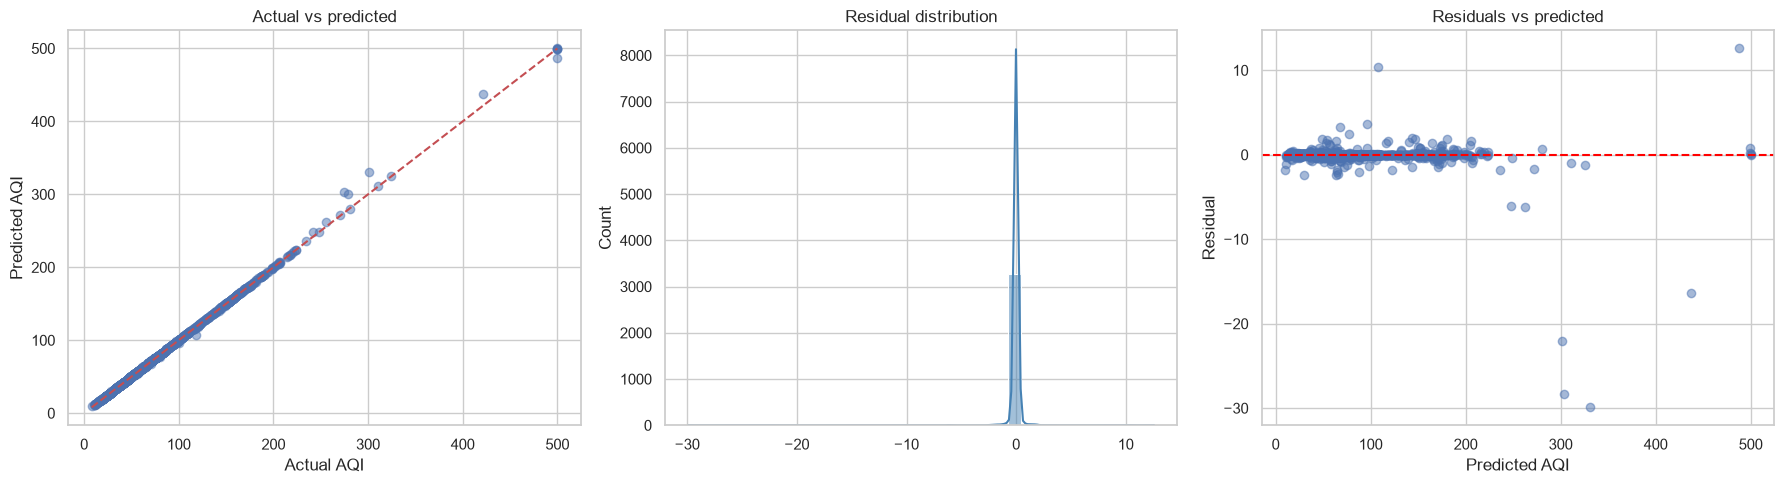

In [7]:
best_aqi_name = aqI_scores.iloc[0]["Model"]
best_aqi_pred = aqi_predictions[best_aqi_name]
print("Best AQI model by held-out RMSE:", best_aqi_name)
print("MAE:", round(mean_absolute_error(y_aqi_test, best_aqi_pred), 3))
print("RMSE:", round(mean_squared_error(y_aqi_test, best_aqi_pred)**0.5, 3))
print("R²:", round(r2_score(y_aqi_test, best_aqi_pred), 4))

residuals = y_aqi_test.to_numpy() - best_aqi_pred
fig, axes = plt.subplots(1, 3, figsize=(18,5))
axes[0].scatter(y_aqi_test, best_aqi_pred, alpha=.5)
lo, hi = min(y_aqi_test.min(), best_aqi_pred.min()), max(y_aqi_test.max(), best_aqi_pred.max())
axes[0].plot([lo,hi],[lo,hi],"r--"); axes[0].set_xlabel("Actual AQI"); axes[0].set_ylabel("Predicted AQI"); axes[0].set_title("Actual vs predicted")
sns.histplot(residuals, bins=35, kde=True, color="steelblue", ax=axes[1]); axes[1].set_title("Residual distribution")
axes[2].scatter(best_aqi_pred, residuals, alpha=.5); axes[2].axhline(0,color="red",linestyle="--"); axes[2].set_xlabel("Predicted AQI"); axes[2].set_ylabel("Residual"); axes[2].set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

fig = px.line(pd.DataFrame({"Actual": y_aqi_test.reset_index(drop=True), "Predicted": best_aqi_pred}).head(250),
              title="AQI actual vs predicted — first 250 held-out rows")
fig.show()
# Permutation importance works across model families, not just tree models.
perm_aqi = permutation_importance(aqi_fitted[best_aqi_name], X_aqi_test, y_aqi_test,
                                  n_repeats=8, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=-1)
imp_aqi = pd.DataFrame({"Feature": pollutants, "Importance mean": perm_aqi.importances_mean,
                        "Importance std": perm_aqi.importances_std}).sort_values("Importance mean")
fig = px.bar(imp_aqi, x="Importance mean", y="Feature", error_x="Importance std", orientation="h",
             title=f"Permutation feature importance — {best_aqi_name}")
fig.show()

## 8. Rainfall exploratory data analysis

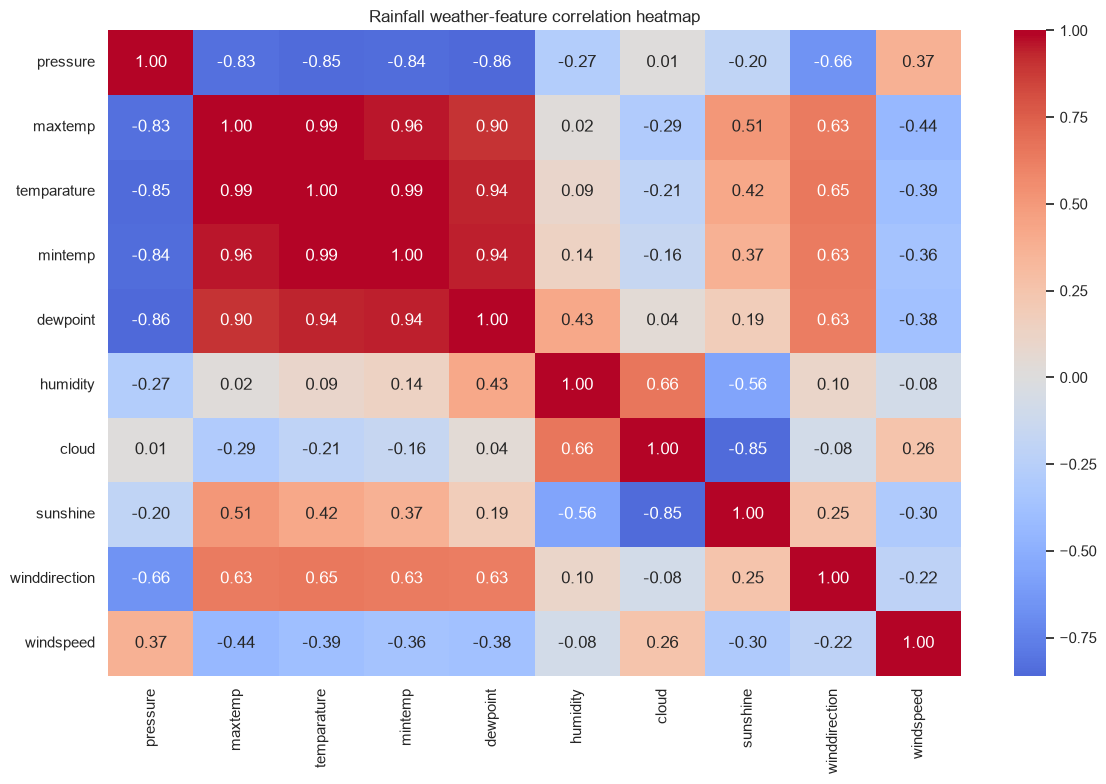

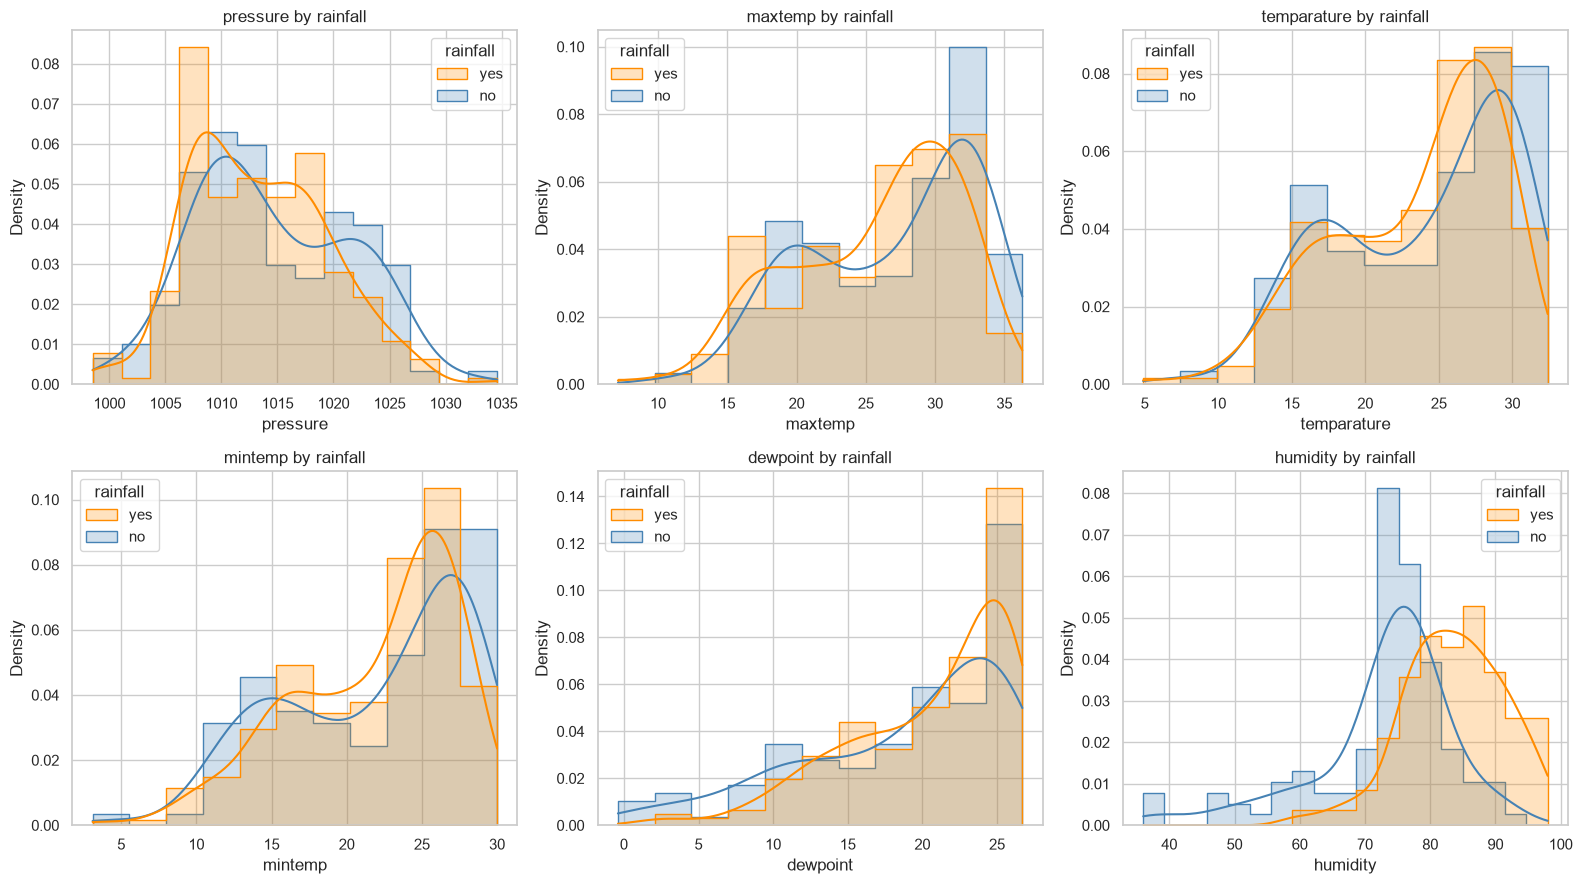

In [8]:
rain_clean = rain[rain["rainfall"].isin(["yes", "no"])].copy()
rain_features = [c for c in rain_clean.select_dtypes(include=np.number).columns if c != "day"]
weather = rain_clean[rain_features]

plt.figure(figsize=(12,8))
sns.heatmap(weather.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Rainfall weather-feature correlation heatmap"); plt.tight_layout(); plt.show()

fig = px.box(rain_clean, x="rainfall", y="humidity", color="rainfall", points="all", title="Humidity by rainfall class")
fig.show()
fig = px.box(rain_clean, x="rainfall", y="cloud", color="rainfall", points="all", title="Cloud cover by rainfall class")
fig.show()
fig = px.box(rain_clean, x="rainfall", y="sunshine", color="rainfall", points="all", title="Sunshine by rainfall class")
fig.show()
fig = px.scatter(rain_clean, x="humidity", y="cloud", color="rainfall", size=rain_clean["windspeed"].fillna(rain_clean["windspeed"].median()),
                 hover_data=["pressure", "sunshine", "maxtemp"], title="Humidity vs cloud cover, colored by rainfall")
fig.show()
fig = px.parallel_coordinates(rain_clean, dimensions=["pressure", "humidity", "cloud", "sunshine", "windspeed"],
                              color=rain_clean["rainfall"].map({"no":0,"yes":1}),
                              title="Parallel coordinates for selected weather variables")
fig.show()

fig, axes = plt.subplots(2, 3, figsize=(16,9))
for ax, col in zip(axes.flat, rain_features[:6]):
    sns.histplot(data=rain_clean, x=col, hue="rainfall", kde=True, element="step", stat="density", common_norm=False, palette={"no":"steelblue", "yes":"darkorange"}, ax=ax)
    ax.set_title(f"{col} by rainfall")
plt.tight_layout(); plt.show()

## 9. Rainfall classification — train and compare models

In [9]:
X_rain = rain_clean[rain_features]
y_rain = rain_clean["rainfall"].map({"no":0, "yes":1}).astype(int)
X_rain_train, X_rain_test, y_rain_train, y_rain_test = train_test_split(
    X_rain, y_rain, test_size=0.20, random_state=RANDOM_STATE, stratify=y_rain
)

rain_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE)
}
if XGBOOST_AVAILABLE:
    rain_models["XGBoost"] = XGBClassifier(n_estimators=350, max_depth=3, learning_rate=0.03,
        subsample=0.9, colsample_bytree=0.9, min_child_weight=2, reg_lambda=2,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

rain_fitted, rain_rows, rain_predictions, rain_probabilities = {}, [], {}, {}
for name, estimator in rain_models.items():
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", estimator)])
    pipe.fit(X_rain_train, y_rain_train)
    pred = pipe.predict(X_rain_test)
    prob = pipe.predict_proba(X_rain_test)[:,1]
    rain_fitted[name], rain_predictions[name], rain_probabilities[name] = pipe, pred, prob
    rain_rows.append({"Model":name, "Accuracy":accuracy_score(y_rain_test,pred),
        "Balanced accuracy":balanced_accuracy_score(y_rain_test,pred),
        "Precision":precision_score(y_rain_test,pred,zero_division=0),
        "Recall":recall_score(y_rain_test,pred,zero_division=0),
        "F1":f1_score(y_rain_test,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(y_rain_test,prob),
        "PR-AUC":average_precision_score(y_rain_test,prob)})
rain_scores = pd.DataFrame(rain_rows).sort_values(["ROC-AUC", "F1"], ascending=False)
display(rain_scores.style.format({c:"{:.3f}" for c in rain_scores.columns if c != "Model"}))
fig = px.bar(rain_scores.melt(id_vars="Model", value_vars=["Accuracy","Precision","Recall","F1","ROC-AUC"],
    var_name="Metric", value_name="Score"), x="Model", y="Score", color="Metric", barmode="group",
    title="Rainfall model comparison")
fig.show()

,Model,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.824,0.816,0.894,0.840,0.866,0.921,0.965
4,Support Vector Machine,0.784,0.764,0.854,0.820,0.837,0.921,0.965
1,Random Forest,0.797,0.774,0.857,0.840,0.848,0.883,0.947
5,XGBoost,0.757,0.701,0.796,0.860,0.827,0.874,0.939
2,Extra Trees,0.797,0.742,0.818,0.900,0.857,0.862,0.936
3,HistGradientBoosting,0.730,0.670,0.778,0.840,0.808,0.818,0.913


## 10. Rainfall diagnostics: confusion matrix, ROC, precision-recall

Best rainfall model by held-out ROC-AUC: Logistic Regression
              precision    recall  f1-score   support

     No rain       0.70      0.79      0.75        24
        Rain       0.89      0.84      0.87        50

    accuracy                           0.82        74
   macro avg       0.80      0.82      0.81        74
weighted avg       0.83      0.82      0.83        74



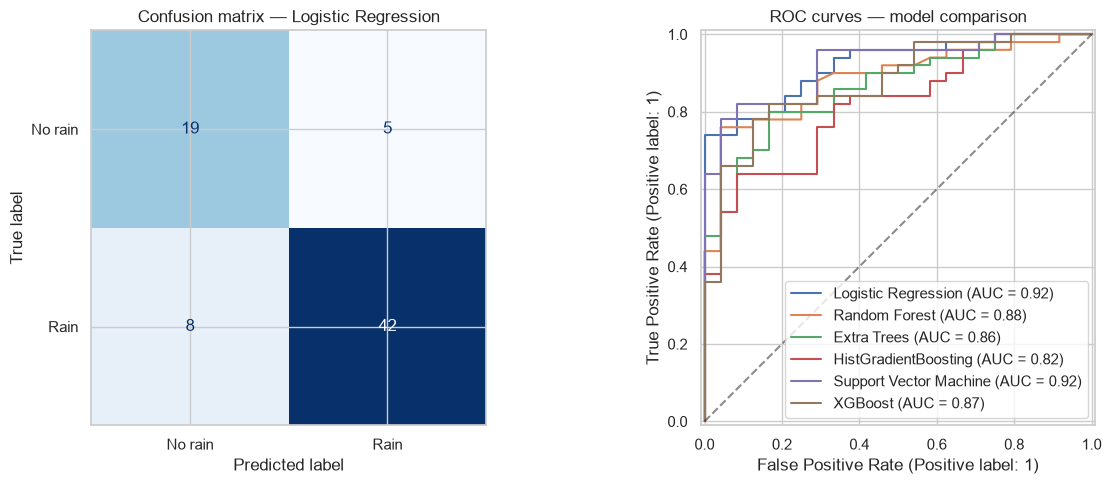

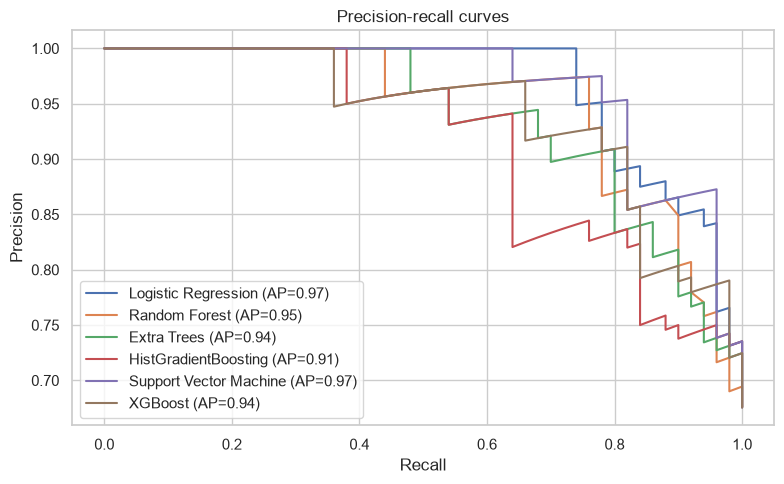

In [10]:
best_rain_name = rain_scores.iloc[0]["Model"]
best_rain_pred = rain_predictions[best_rain_name]
best_rain_prob = rain_probabilities[best_rain_name]
print("Best rainfall model by held-out ROC-AUC:", best_rain_name)
print(classification_report(y_rain_test, best_rain_pred, target_names=["No rain", "Rain"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13,5))
ConfusionMatrixDisplay.from_predictions(y_rain_test, best_rain_pred, display_labels=["No rain","Rain"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix — {best_rain_name}")
for name in rain_fitted:
    RocCurveDisplay.from_predictions(y_rain_test, rain_probabilities[name], name=name, ax=axes[1])
axes[1].plot([0,1],[0,1],"k--",alpha=.5); axes[1].set_title("ROC curves — model comparison")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
for name in rain_fitted:
    precision, recall, _ = precision_recall_curve(y_rain_test, rain_probabilities[name])
    ap = average_precision_score(y_rain_test, rain_probabilities[name])
    plt.plot(recall, precision, label=f"{name} (AP={ap:.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall curves"); plt.legend(); plt.tight_layout(); plt.show()

fig = px.histogram(pd.DataFrame({"Predicted probability of rain":best_rain_prob,
                                  "Actual class":y_rain_test.map({0:"No rain",1:"Rain"}).to_numpy()}),
                   x="Predicted probability of rain", color="Actual class", nbins=20,
                   barmode="overlay", opacity=.7, title="Predicted rainfall probabilities by true class")
fig.show()

## 11. Rainfall feature importance

In [11]:
perm_rain = permutation_importance(rain_fitted[best_rain_name], X_rain_test, y_rain_test,
    n_repeats=12, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
imp_rain = pd.DataFrame({"Feature":rain_features, "Importance mean":perm_rain.importances_mean,
                         "Importance std":perm_rain.importances_std}).sort_values("Importance mean")
fig = px.bar(imp_rain, x="Importance mean", y="Feature", error_x="Importance std", orientation="h",
             title=f"Rainfall permutation feature importance — {best_rain_name}")
fig.show()

## 12. Cross-validation on training data

In [12]:
# Cross-validation uses only the training split, leaving the held-out test set untouched.
# Rainfall's small sample size makes fold-to-fold variability especially important.
cv_rows = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, estimator in rain_models.items():
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", estimator)])
    scores = cross_validate(pipe, X_rain_train, y_rain_train, cv=cv,
        scoring={"f1":"f1", "roc_auc":"roc_auc", "accuracy":"accuracy"}, n_jobs=1)
    cv_rows.append({"Model":name, "CV F1 mean":scores["test_f1"].mean(), "CV F1 std":scores["test_f1"].std(),
                    "CV ROC-AUC mean":scores["test_roc_auc"].mean(), "CV ROC-AUC std":scores["test_roc_auc"].std(),
                    "CV accuracy mean":scores["test_accuracy"].mean()})
rain_cv_scores = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC mean", ascending=False)
display(rain_cv_scores.style.format({c:"{:.3f}" for c in rain_cv_scores.columns if c != "Model"}))
fig = px.bar(rain_cv_scores, x="Model", y="CV ROC-AUC mean", error_y="CV ROC-AUC std",
             title="Rainfall 5-fold training CV ROC-AUC (mean ± standard deviation)")
fig.show()

,Model,CV F1 mean,CV F1 std,CV ROC-AUC mean,CV ROC-AUC std,CV accuracy mean
2,Extra Trees,0.873,0.027,0.851,0.022,0.819
0,Logistic Regression,0.831,0.034,0.848,0.025,0.777
1,Random Forest,0.817,0.020,0.836,0.021,0.757
4,Support Vector Machine,0.829,0.016,0.832,0.028,0.771
3,HistGradientBoosting,0.834,0.032,0.817,0.031,0.771
5,XGBoost,0.845,0.029,0.807,0.040,0.781


## 13. Try predictions with the best evaluated models

In [13]:
# AQI prediction: enter pollutant AQI values below. Values should be within plausible ranges for your data.
aqI_input = pd.DataFrame([{
    "co aqi value": 1,
    "ozone aqi value": 30,
    "no2 aqi value": 5,
    "pm2.5 aqi value": 40
}])
aqI_estimate = float(aqi_fitted[best_aqi_name].predict(aqI_input)[0])
print(f"Estimated AQI using {best_aqi_name}: {aqI_estimate:.1f}")

# Rainfall prediction: replace values below with the current weather observations.
rain_input = pd.DataFrame([{
    "pressure": 1015.0, "maxtemp": 28.0, "temparature": 25.0, "mintemp": 22.0,
    "dewpoint": 20.0, "humidity": 75, "cloud": 60, "sunshine": 4.0,
    "winddirection": 180.0, "windspeed": 12.0
}], columns=rain_features)
rain_class = int(rain_fitted[best_rain_name].predict(rain_input)[0])
rain_probability = float(rain_fitted[best_rain_name].predict_proba(rain_input)[0,1])
print(f"Rainfall prediction using {best_rain_name}: {'YES' if rain_class else 'NO'}")
print(f"Estimated probability of rain: {rain_probability:.1%}")
print("Note: example inputs only; these are model estimates, not official forecasts.")

Estimated AQI using Extra Trees: 40.0
Rainfall prediction using Logistic Regression: NO
Estimated probability of rain: 32.2%
Note: example inputs only; these are model estimates, not official forecasts.


## 14. Export evaluation tables and final notes

In [14]:
aqI_scores.to_csv("aqi_model_comparison.csv", index=False)
rain_scores.to_csv("rainfall_model_comparison.csv", index=False)
rain_cv_scores.to_csv("rainfall_cross_validation.csv", index=False)
print("Saved: aqi_model_comparison.csv, rainfall_model_comparison.csv, rainfall_cross_validation.csv")
print("\nAQI best by test RMSE:", aqI_scores.iloc[0]["Model"])
print("Rainfall best by test ROC-AUC:", rain_scores.iloc[0]["Model"])
print("\nImportant limitations:")
print("1. AQI uses pollutant AQI values that are closely linked to the overall AQI target; this is estimation, not future forecasting.")
print("2. The rainfall dataset has only 366 rows. Use cross-validation variability and avoid overclaiming performance.")
print("3. Model choice should consider the relevant error costs, not only one score.")

Saved: aqi_model_comparison.csv, rainfall_model_comparison.csv, rainfall_cross_validation.csv

AQI best by test RMSE: Extra Trees
Rainfall best by test ROC-AUC: Logistic Regression

Important limitations:
1. AQI uses pollutant AQI values that are closely linked to the overall AQI target; this is estimation, not future forecasting.
2. The rainfall dataset has only 366 rows. Use cross-validation variability and avoid overclaiming performance.
3. Model choice should consider the relevant error costs, not only one score.


## 15. Deployment export: save models for Streamlit app

This cell trains the deployment models on the full available datasets and saves them with `joblib`. The Streamlit frontend (`app.py`) loads these exact files; it does not retrain models. Run this cell whenever you change the training data, features, or model settings.

Files created: `models/aqi_model.joblib` and `models/rainfall_model.joblib`.

In [15]:
import joblib
from pathlib import Path

# Use the same fixed feature lists and estimators as app.py.
AQI_FEATURES = ["co aqi value", "ozone aqi value", "no2 aqi value", "pm2.5 aqi value"]
RAIN_FEATURES = ["pressure", "maxtemp", "temparature", "mintemp", "dewpoint", "humidity", "cloud", "sunshine", "winddirection", "windspeed"]
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# AQI deployment pipeline: impute missing values, then Extra Trees regression.
aqi_export_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)),
])
aqi_export_data = aqi.dropna(subset=["aqi value"]).copy()
aqi_export_X = aqi_export_data[AQI_FEATURES]
aqi_export_y = aqi_export_data["aqi value"]
aqi_export_model.fit(aqi_export_X, aqi_export_y)
joblib.dump({"model": aqi_export_model, "features": AQI_FEATURES, "model_name": "Extra Trees Regressor", "metrics": {"MAE": float(aqI_scores.loc[aqI_scores["Model"] == "Extra Trees", "MAE"].iloc[0]), "RMSE": float(aqI_scores.loc[aqI_scores["Model"] == "Extra Trees", "RMSE"].iloc[0]), "R2": float(aqI_scores.loc[aqI_scores["Model"] == "Extra Trees", "R2"].iloc[0])}, "target": "aqi value", "version": 1}, MODEL_DIR / "aqi_model.joblib")

# Rainfall deployment pipeline: median imputation, scaling, then logistic regression.
rain_export_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
])
rain_export_data = rain[rain["rainfall"].isin(["yes", "no"])].copy()
rain_export_X = rain_export_data[RAIN_FEATURES]
rain_export_y = rain_export_data["rainfall"].map({"no": 0, "yes": 1}).astype(int)
rain_export_model.fit(rain_export_X, rain_export_y)
joblib.dump({"model": rain_export_model, "features": RAIN_FEATURES, "model_name": "Logistic Regression", "metrics": {"Accuracy": float(rain_scores.loc[rain_scores["Model"] == "Logistic Regression", "Accuracy"].iloc[0]), "ROC-AUC": float(rain_scores.loc[rain_scores["Model"] == "Logistic Regression", "ROC-AUC"].iloc[0])}, "target": "rainfall (0=no, 1=yes)", "version": 1}, MODEL_DIR / "rainfall_model.joblib")

print("Saved models for app.py:")
print((MODEL_DIR / "aqi_model.joblib").resolve())
print((MODEL_DIR / "rainfall_model.joblib").resolve())
print("The Streamlit app loads these saved models and does not retrain them.")


Saved models for app.py:
C:\Users\swaru\OneDrive\Desktop\ML\ML Project\models\aqi_model.joblib
C:\Users\swaru\OneDrive\Desktop\ML\ML Project\models\rainfall_model.joblib
The Streamlit app loads these saved models and does not retrain them.
